In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable, update_column
from PlateDict import wellMap

pd.options.display.max_rows = 1000

pd.options.display.max_columns = 60


A01
31


In [2]:
from PlateDict import rev_wellMap, wellMap, MakeCPFiles

In [3]:
import glob
from matplotlib_venn import venn2, venn3

# XP data

In [4]:
res = {}
for elem in glob.glob('data/*'):
    if 'Plate' in elem:
        
        retest_pla = int(elem.split('_')[1][-2:])

        
        df = pd.read_excel(elem, skiprows=10, skipfooter=35)
        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
        
        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')
                
                res[key] = value
                

*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 

# retest table

In [5]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       
       'db_symbol', 'retest_pla', 'retest_pos',
       'standard_batch', 'variant_id']


query = f'select distinct { ", ".join(c for c in col)} from vus.retest where `standard_batch` in ("yN2Hwtpwt");'

yN2H_retest = GetDFv2(query, col)
yN2H_retest['yN2H_score'] = [res[(pla, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score
0,0,None,71258,CTNNA3,1,A01,yN2Hwtpwt,empty_N1,124
1,9580,GPR161,0,None,1,B01,yN2Hwtpwt,empty_N2,206
2,53053,CCHCR1,386,STAR,1,C01,yN2Hwtpwt,litbm,96
3,52859,CCDC136,54082,PRPF31,1,D01,yN2Hwtpwt,wt,89
4,644,ITPK1,0,None,1,F01,yN2Hwtpwt,empty_N2,124


In [6]:
yN2H_retest.variant_id.value_counts()

wt                  699
empty_N2            633
empty_N1            278
RRS                  78
PRS                  60
litbm                56
NCBP1_NCBP2_ctrl     42
SKP1_SKP2_ctrl       42
Name: variant_id, dtype: int64

# plate controls


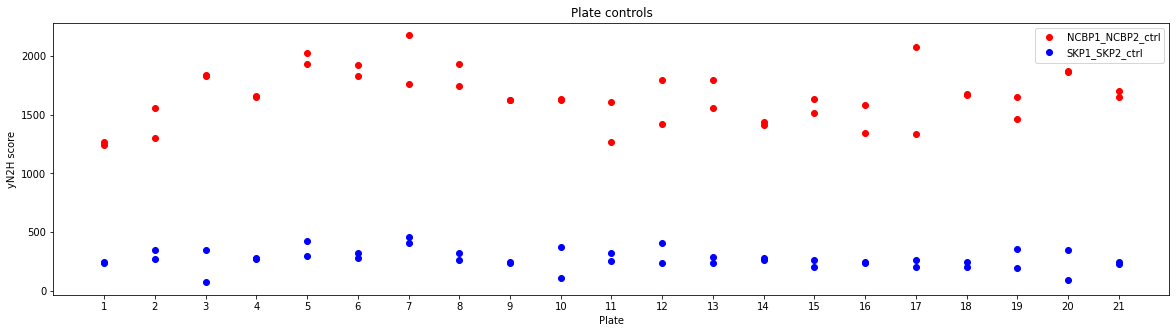

In [7]:
plt.figure(figsize=(20,5))

df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score.tolist(), 'ro', color='r', label='NCBP1_NCBP2_ctrl')

df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl')


plt.title('Plate controls')

plt.xlabel('Plate')

plt.xticks([i for i in range(1,22)])
plt.ylabel('yN2H score')

plt.legend()
plt.savefig('control_plate.pdf')


plt.show()

In [8]:
np.std(yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])].yN2H_score.tolist())

224.20877383153083

In [9]:
np.std(yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])].yN2H_score.tolist())


80.36848244505767

In [10]:
np.std(yN2H_retest[yN2H_retest.variant_id.isin(['empty_N2'])].yN2H_score.tolist())


2480.8267414240436

In [11]:
np.std(yN2H_retest[yN2H_retest.variant_id.isin(['empty_N1'])].yN2H_score.tolist())


999.875807566832

# Normalized lumination ratio


In [12]:
#empty_N1_df = yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].copy()
#empty_N2_df = yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].copy()

empty_N1_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score))
empty_N2_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score))


yN2H_normalized = yN2H_retest[yN2H_retest.variant_id.isin(['wt','RRS','PRS','litbm'])].copy()
yN2H_normalized['pair'] = [tuple(sorted([x,y])) for x, y in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['variant_idv2'] = yN2H_normalized.variant_id.apply(lambda x: x if x !=  'litbm' else 'wt')

yN2H_normalized['empty_N1'] = yN2H_normalized.db_orf_id.map(empty_N1_d)
yN2H_normalized['empty_N2'] = yN2H_normalized.ad_orf_id.map(empty_N2_d)

yN2H_normalized['NLR'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]
yN2H_normalized['detected'] = yN2H_normalized.NLR.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.max())

yN2H_normalized['detectedv2'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-4])




yN2H_normalized['NLR_log2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]


yN2H_normalized.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,detected,detectedv2,NLR_log2
2,53053,CCHCR1,386,STAR,1,C01,yN2Hwtpwt,litbm,96,"(386, 53053)",wt,179,151,0.536313,False,False,-0.898853
3,52859,CCDC136,54082,PRPF31,1,D01,yN2Hwtpwt,wt,89,"(52859, 54082)",wt,261,165,0.340996,False,False,-1.552173
8,6759,RPS27A,52920,LITAF,1,B02,yN2Hwtpwt,wt,103,"(6759, 52920)",wt,137,2479,0.041549,False,False,-4.589042
11,70408,OXER1,5933,TFG,1,E02,yN2Hwtpwt,wt,69,"(5933, 70408)",wt,199,89,0.346734,False,False,-1.528100
12,14862,GOLGA2,54459,RNF135,1,F02,yN2Hwtpwt,wt,144,"(14862, 54459)",wt,185,920,0.156522,False,False,-2.675565


In [15]:
yN2H_normalized[['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol', 'retest_pla',
       'retest_pos', 'standard_batch', 'variant_id', 'yN2H_score',
       'variant_idv2', 'empty_N1', 'empty_N2']].to_csv('yN2H_wtpwt_raw.csv')

In [13]:
yN2H_normalized[yN2H_normalized.variant_id.isin(['wt','litbm'])].pair.nunique()

753

Text(0, 0.5, 'count')

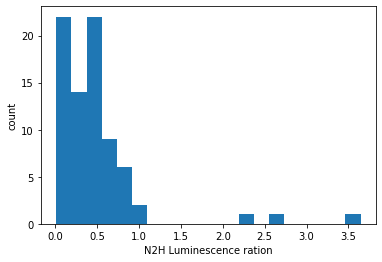

In [14]:
yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.plot.hist(bins=20)
plt.xlabel('N2H Luminescence ration')
plt.ylabel('count')







In [15]:
sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-2]

2.6790123456790123

# PRS-RRS comparison


In [16]:
prs_df = yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].copy()

col =  ['ad_orf_id', 'db_orf_id', 'retest_type', 'positive_SG', 'positive_old','positive_GFP', 'NLR_old_log2', 'NLR_GFP_log2', 'NLR_SG_log2']
previous_prs_df  = pd.read_csv('../20210223_yN2H_PRS/yN2H_PRS_RRS_table.csv', sep='\t', index_col=0)

prs_df =  prs_df.merge(previous_prs_df[col], on=['ad_orf_id', 'db_orf_id'])



prs_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,detected,detectedv2,NLR_log2,retest_type,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,3621,CD81,7941,NPC2,1,B03,yN2Hwtpwt,RRS,76,"(3621, 7941)",RRS,96,515,0.147573,False,False,-2.760501,RRS,False,False,False,-0.299560,-1.718818,-1.725975
1,7772,PSMD12,5546,CRIPT,1,F04,yN2Hwtpwt,RRS,96,"(5546, 7772)",RRS,82,240,0.400000,False,False,-1.321928,RRS,False,False,False,-0.739764,-0.285402,-3.821796
2,4958,ATF3,3944,DDIT3,1,D05,yN2Hwtpwt,PRS,886,"(3944, 4958)",PRS,110,172,5.151163,True,True,2.364898,PRS,False,True,True,2.365476,1.790711,0.287552
3,5545,LUM,9673,UGGT2,1,F05,yN2Hwtpwt,RRS,76,"(5545, 9673)",RRS,117,151,0.503311,False,False,-0.990477,RRS,False,False,False,-0.812373,-0.898853,-0.842899
4,1938,CBLB,8010,GRB2,1,A06,yN2Hwtpwt,PRS,3090,"(1938, 8010)",PRS,378,597,5.175879,True,True,2.371804,PRS,True,True,True,3.097238,2.328508,2.099091


In [17]:
col = ['ad_symbol', 'db_symbol',  'yN2H_score',
       
       'empty_N1', 'empty_N2', 'NLR', 'detectedv2', 'NLR_log2',
       
       'NLR_old_log2', 'NLR_GFP_log2', 'NLR_SG_log2']


In [18]:
prs_df[(prs_df.NLR_log2 > 1)&(prs_df.variant_id == 'RRS')][col]

,ad_symbol,db_symbol,yN2H_score,empty_N1,empty_N2,NLR,detectedv2,NLR_log2,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
36,NKX2-5,CSGALNACT2,1085,378,405,2.679012,True,1.421701,-1.317740,0.486760,-3.593877
37,SLC6A1,TM4SF4,433,130,185,2.340541,True,1.226842,-0.256204,1.173431,-1.052723
66,ERBB3,C3orf38,900,247,110,3.643725,True,1.865414,-0.898853,-2.179746,-1.693376


Text(0, 0.5, 'N2H luminescence ratio PRS-RRS')

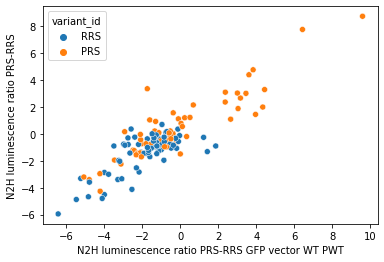

In [19]:
sns.scatterplot(data=prs_df, x='NLR_log2', y='NLR_old_log2', hue='variant_id')
plt.xlabel('N2H luminescence ratio PRS-RRS GFP vector WT PWT')
plt.ylabel('N2H luminescence ratio PRS-RRS')


Text(0, 0.5, 'N2H luminescence ratio PRS-RRS GFP vector')

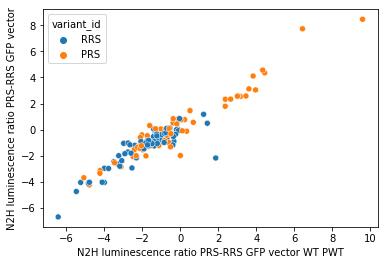

In [20]:
sns.scatterplot(data=prs_df, x='NLR_log2', y='NLR_GFP_log2', hue='variant_id')
plt.xlabel('N2H luminescence ratio PRS-RRS GFP vector WT PWT')
plt.ylabel('N2H luminescence ratio PRS-RRS GFP vector')


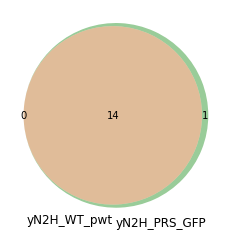

In [21]:
venn2([set(prs_df[prs_df.detected  == True].pair),set(prs_df[prs_df.positive_GFP  == True].pair)],
      ['yN2H_WT_pwt', 'yN2H_PRS_GFP']
     )

In [22]:
14/60

0.23333333333333334

## controls

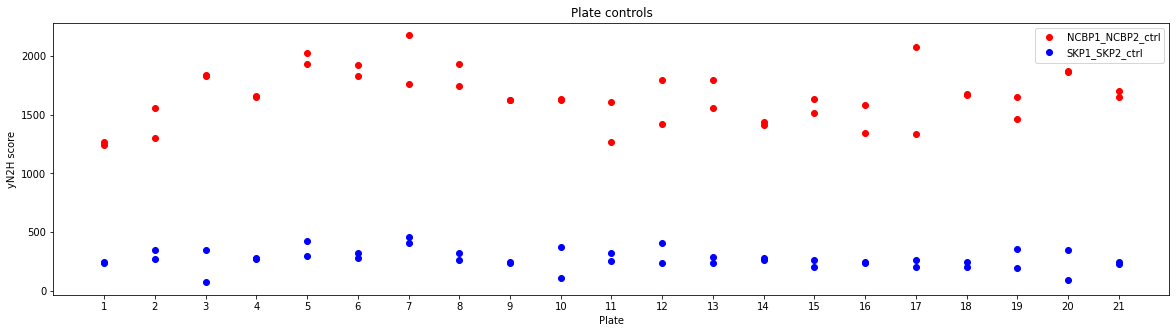

In [66]:
plt.figure(figsize=(20,5))
df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score.tolist(), 'ro', color='r', label='NCBP1_NCBP2_ctrl')
df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl')
plt.title('Plate controls')
plt.xlabel('Plate')
plt.xticks([i for i in range(1,22)])
plt.ylabel('yN2H score')
plt.legend()
plt.show()

In [69]:
prs_df[prs_df.ad_symbol.isin(['NCBP1','NCBP2'])]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,detected,detectedv2,NLR_log2,retest_type,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
6,7450,NCBP1,2754,NCBP2,2,A01,yN2Hwtpwt,PRS,1641,"(2754, 7450)",PRS,96,2143,0.765749,False,False,-0.385057,PRS,True,False,False,0.023946,0.506117,0.48885


In [70]:
prs_df[prs_df.ad_symbol.isin(['SKP1','SKP2'])]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,detected,detectedv2,NLR_log2,retest_type,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
82,6671,SKP1,4656,SKP2,13,H07,yN2Hwtpwt,PRS,233,"(4656, 6671)",PRS,103,227,1.026432,False,True,0.037638,PRS,False,True,False,0.778442,0.750280,-1.709489
90,6671,SKP1,9477,BTRC,14,D07,yN2Hwtpwt,PRS,3028,"(6671, 9477)",PRS,247,227,12.259109,True,True,3.615782,PRS,True,True,True,4.392015,3.123278,4.620473


In [67]:
prs_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,detected,detectedv2,NLR_log2,retest_type,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,3621,CD81,7941,NPC2,1,B03,yN2Hwtpwt,RRS,76,"(3621, 7941)",RRS,96,515,0.147573,False,False,-2.760501,RRS,False,False,False,-0.299560,-1.718818,-1.725975
1,7772,PSMD12,5546,CRIPT,1,F04,yN2Hwtpwt,RRS,96,"(5546, 7772)",RRS,82,240,0.400000,False,False,-1.321928,RRS,False,False,False,-0.739764,-0.285402,-3.821796
2,4958,ATF3,3944,DDIT3,1,D05,yN2Hwtpwt,PRS,886,"(3944, 4958)",PRS,110,172,5.151163,True,True,2.364898,PRS,False,True,True,2.365476,1.790711,0.287552
3,5545,LUM,9673,UGGT2,1,F05,yN2Hwtpwt,RRS,76,"(5545, 9673)",RRS,117,151,0.503311,False,False,-0.990477,RRS,False,False,False,-0.812373,-0.898853,-0.842899
4,1938,CBLB,8010,GRB2,1,A06,yN2Hwtpwt,PRS,3090,"(1938, 8010)",PRS,378,597,5.175879,True,True,2.371804,PRS,True,True,True,3.097238,2.328508,2.099091


# How many WT?


<AxesSubplot:xlabel='variant_id', ylabel='NLR'>

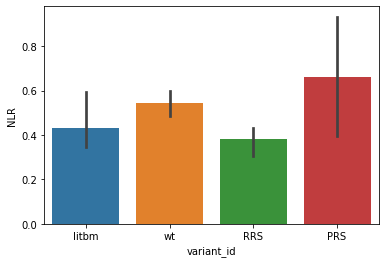

In [23]:
sns.barplot(data=yN2H_normalized, x='variant_id', y='NLR', estimator=np.median)

<AxesSubplot:xlabel='variant_id', ylabel='detected'>

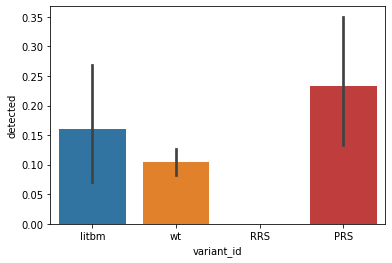

In [24]:
sns.barplot(data=yN2H_normalized, x='variant_id', y='detected')


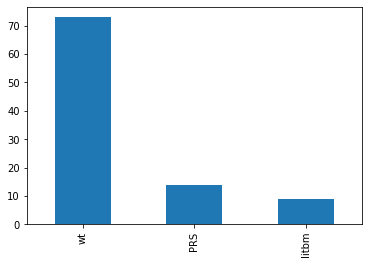

In [25]:
yN2H_normalized[yN2H_normalized.detected].variant_id.value_counts().plot.bar();

82
0.10860927152317881


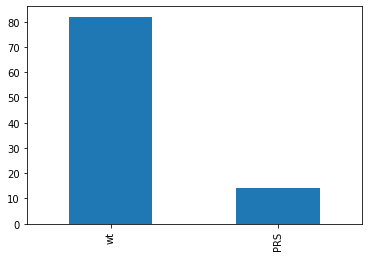

In [26]:
print(yN2H_normalized[yN2H_normalized.variant_idv2=='wt'].detected.sum())
print(82/755)

yN2H_normalized[yN2H_normalized.detected].variant_idv2.value_counts().plot.bar();

229
0.13642384105960265


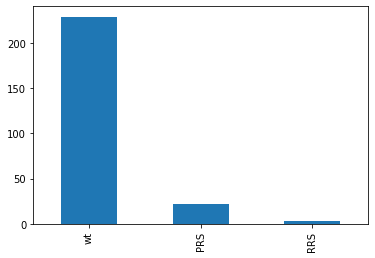

In [27]:
yN2H_normalized['detectedv2'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-4])




print(yN2H_normalized[yN2H_normalized.variant_idv2=='wt'].detectedv2.sum())

print(103/755)





yN2H_normalized[yN2H_normalized.detectedv2].variant_idv2.value_counts().plot.bar();


In [28]:
N2H_validation_nodes = GetDF('vus','N2H_validation_nodes')
N2H_validation_nodes = N2H_validation_nodes[(N2H_validation_nodes.N2H_GDEh_plate.str.contains('mut'))&(N2H_validation_nodes.bact_cloned == 1)]
n_allele_d = dict(N2H_validation_nodes.symbol.value_counts())


N2H_validation_nodes.head()

,orf_id,symbol,node_type,mut_id,source_plate,source_well,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,N2H_GFP11,yeast_cloned,pdest_dual_plate,pdest_dual_well
963,12573,DES,allele,2217.0,VUSMutGDEh002,C12,VUSN2Hmut_GDEh_1,A01,vus,1,1,1,0,None,None
964,12573,DES,allele,2218.0,VUSMutGDEh002,D12,VUSN2Hmut_GDEh_1,B01,vus,1,1,1,0,None,None
965,12573,DES,allele,2223.0,VUSMutGDEh003,C01,VUSN2Hmut_GDEh_1,C01,vus,1,1,1,0,None,None
966,12573,DES,allele,2225.0,VUSMutGDEh003,E01,VUSN2Hmut_GDEh_1,D01,vus,1,1,1,0,None,None
968,12573,DES,allele,2229.0,VUSMutGDEh003,H01,VUSN2Hmut_GDEh_1,F01,vus,1,1,1,0,None,None


# allele pairwise test count


In [29]:
yN2H_normalized['detected_0'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-1])
yN2H_normalized['detected_1'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-2])
yN2H_normalized['detected_2'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-3])
yN2H_normalized['detected_3'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-4])






by_gene_df = pd.DataFrame([pd.Series(dict(yN2H_normalized[(yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts())),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_0 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_1 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_2 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_3 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts())
                           
                          ]).T


by_gene_df.columns = ['y2h', 'n2h_0','n2h_1','n2h_2', 'n2h_3']
by_gene_df.fillna(0, inplace=True)
by_gene_df['n_alleles'] = by_gene_df.index.map(n_allele_d)
by_gene_df.sort_values(by='n2h_0', ascending=False, inplace=True)

for c in ['n2h_0','n2h_1','n2h_2','n2h_3']:
    by_gene_df[f'{c}_n_test'] = by_gene_df[c] * by_gene_df.n_alleles + 1
    

by_gene_df.head(40)

,y2h,n2h_0,n2h_1,n2h_2,n2h_3,n_alleles,n2h_0_n_test,n2h_1_n_test,n2h_2_n_test,n2h_3_n_test
PLP1,20.0,7.0,11.0,13.0,18.0,13.0,92.0,144.0,170.0,235.0
CLDN19,16.0,7.0,7.0,9.0,12.0,1.0,8.0,8.0,10.0,13.0
IER3IP1,7.0,4.0,4.0,4.0,6.0,2.0,9.0,9.0,9.0,13.0
SFTPC,6.0,4.0,4.0,4.0,6.0,5.0,21.0,21.0,21.0,31.0
GOSR2,8.0,4.0,4.0,4.0,5.0,1.0,5.0,5.0,5.0,6.0
MIP,8.0,3.0,3.0,3.0,6.0,1.0,4.0,4.0,4.0,7.0
KRT83,7.0,3.0,3.0,3.0,5.0,1.0,4.0,4.0,4.0,6.0
CUL3,11.0,3.0,4.0,5.0,8.0,1.0,4.0,5.0,6.0,9.0
TPM1,5.0,2.0,2.0,2.0,4.0,27.0,55.0,55.0,55.0,109.0
PRKAR1A,4.0,2.0,2.0,2.0,2.0,4.0,9.0,9.0,9.0,9.0


In [30]:
by_gene_df[by_gene_df.index.isin(['MLH1', 'MVK', 'AGXT','STXBP1'])]

,y2h,n2h_0,n2h_1,n2h_2,n2h_3,n_alleles,n2h_0_n_test,n2h_1_n_test,n2h_2_n_test,n2h_3_n_test
MLH1,16.0,1.0,1.0,1.0,6.0,40.0,41.0,41.0,41.0,241.0
MVK,1.0,0.0,1.0,1.0,1.0,32.0,1.0,33.0,33.0,33.0
AGXT,6.0,0.0,0.0,0.0,0.0,45.0,1.0,1.0,1.0,1.0
STXBP1,4.0,0.0,0.0,0.0,3.0,40.0,1.0,1.0,1.0,121.0


In [31]:
by_gene_df.index.tolist()

['PLP1',
 'CLDN19',
 'IER3IP1',
 'SFTPC',
 'GOSR2',
 'MIP',
 'KRT83',
 'CUL3',
 'TPM1',
 'PRKAR1A',
 'BANF1',
 'TPM3',
 'TFG',
 'AMPD2',
 'FBP1',
 'NMNAT1',
 'XRCC2',
 'KRT2',
 'TRAF3',
 'PYGL',
 'TMEM43',
 'MID1',
 'THAP1',
 'CHN1',
 'LDHB',
 'FA2H',
 'PUF60',
 'POLR1C',
 'PIK3CD',
 'RP2',
 'PRPS1',
 'KCTD1',
 'SH3BP2',
 'PHYKPL',
 'TH',
 'IL36RN',
 'GALE',
 'TAT',
 'AP2S1',
 'TPK1',
 'PNKP',
 'NCF2',
 'MLH1',
 'UNC119',
 'UBQLN2',
 'KCNJ2',
 'BAG3',
 'DOLK',
 'KRT4',
 'HPRT1',
 'SERPINE1',
 'NEXN',
 'POMT1',
 'MVK',
 'GMPPB',
 'KLHL3',
 'COG4',
 'STAC3',
 'HCFC1',
 'FXN',
 'PHYH',
 'ORC6',
 'SFTPB',
 'CCBE1',
 'CSNK1D',
 'SMAD1',
 'GSS',
 'CRADD',
 'IRAK4',
 'NF2',
 'SNIP1',
 'ASNS',
 'VAPB',
 'ALAS2',
 'RAB33B',
 'TTR',
 'SMARCB1',
 'HBD',
 'WRAP53',
 'CLCNKA',
 'FGD4',
 'VHL',
 'APOA1',
 'LRRC6',
 'FAM187A',
 'EXOC8',
 'PITX2',
 'GFAP',
 'DIABLO',
 'CDC73',
 'NFU1',
 'XPA',
 'SS18L1',
 'TTPA',
 'AGXT',
 'MSRB3',
 'KRT86',
 'PMP22',
 'KCTD7',
 'DES',
 'IMPDH1',
 'GLYCTK',
 'LITAF',


In [32]:
for c in ['n2h_0','n2h_1','n2h_2','n2h_3']:
    print(by_gene_df[c].sum())
    
          

82.0
103.0
117.0
229.0


In [33]:
by_gene_df.n2h_3_n_test.sum()





1579.0

# output table, update server, and CP files




In [34]:
yN2H_normalized.variant_idv2.value_counts()


wt     755
RRS     78
PRS     60
Name: variant_idv2, dtype: int64

In [35]:
yN2H_normalized['n_alleles'] = yN2H_normalized.db_symbol.map(n_allele_d)
x = yN2H_normalized[(yN2H_normalized.detected_3 == True)&(yN2H_normalized.variant_idv2 == 'wt')][['db_symbol','n_alleles']].drop_duplicates()

x.n_alleles.sum() / 96







5.375

In [36]:
1450/96


15.104166666666666

## CP files


In [37]:
N2H_validation_nodes.node_type.value_counts()


allele    885
Name: node_type, dtype: int64

In [38]:
selected_wt_orfs = yN2H_normalized[(yN2H_normalized.detected_3 == True)&(yN2H_normalized.variant_idv2 == 'wt')].db_orf_id.unique().tolist()

col = ['orf_id', 'symbol', 'node_type', 'mut_id','N2H_GDEh_plate', 'N2H_GDEh_well', 'collection',
       'bact_cloned', 'bact_monoclonal']

cp_df = N2H_validation_nodes[N2H_validation_nodes.orf_id.isin(selected_wt_orfs)][col].copy()
cp_df['pla'] = cp_df.N2H_GDEh_plate.apply(lambda x: int(x.split('_')[-1]))
cp_df.sort_values(by=['pla', 'N2H_GDEh_plate'], inplace=True)


cp_df['yN2H_GDFEh_plate'] = [f'VUSyN2Hmut_GDEh_{(i//94)+1}' for i in range(len(cp_df))]
cp_df['yN2H_GDFEh_well'] = [rev_wellMap[(i%94)+1] for i in range(len(cp_df))]

cp_df.head()

,orf_id,symbol,node_type,mut_id,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,pla,yN2H_GDFEh_plate,yN2H_GDFEh_well
1109,7652,STXBP1,allele,1790.0,VUSN2Hmut_GDEh_2,E07,vus,1,1,2,VUSyN2Hmut_GDEh_1,A01
1110,7652,STXBP1,allele,1794.0,VUSN2Hmut_GDEh_2,F07,vus,1,1,2,VUSyN2Hmut_GDEh_1,B01
1111,7652,STXBP1,allele,1798.0,VUSN2Hmut_GDEh_2,G07,vus,1,1,2,VUSyN2Hmut_GDEh_1,C01
1112,7652,STXBP1,allele,1799.0,VUSN2Hmut_GDEh_2,H07,vus,1,1,2,VUSyN2Hmut_GDEh_1,D01
1113,7652,STXBP1,allele,1800.0,VUSN2Hmut_GDEh_2,A08,vus,1,1,2,VUSyN2Hmut_GDEh_1,E01


In [39]:
cp_df[cp_df.symbol.isin(['MLH1', 'MVK', 'AGXT','STXBP1'])]

,orf_id,symbol,node_type,mut_id,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,pla,yN2H_GDFEh_plate,yN2H_GDFEh_well
1109,7652,STXBP1,allele,1790.0,VUSN2Hmut_GDEh_2,E07,vus,1,1,2,VUSyN2Hmut_GDEh_1,A01
1110,7652,STXBP1,allele,1794.0,VUSN2Hmut_GDEh_2,F07,vus,1,1,2,VUSyN2Hmut_GDEh_1,B01
1111,7652,STXBP1,allele,1798.0,VUSN2Hmut_GDEh_2,G07,vus,1,1,2,VUSyN2Hmut_GDEh_1,C01
1112,7652,STXBP1,allele,1799.0,VUSN2Hmut_GDEh_2,H07,vus,1,1,2,VUSyN2Hmut_GDEh_1,D01
1113,7652,STXBP1,allele,1800.0,VUSN2Hmut_GDEh_2,A08,vus,1,1,2,VUSyN2Hmut_GDEh_1,E01
1114,7652,STXBP1,allele,1801.0,VUSN2Hmut_GDEh_2,B08,vus,1,1,2,VUSyN2Hmut_GDEh_1,F01
1115,7652,STXBP1,allele,1802.0,VUSN2Hmut_GDEh_2,C08,vus,1,1,2,VUSyN2Hmut_GDEh_1,G01
1116,7652,STXBP1,allele,1803.0,VUSN2Hmut_GDEh_2,D08,vus,1,1,2,VUSyN2Hmut_GDEh_1,H01
1117,7652,STXBP1,allele,1805.0,VUSN2Hmut_GDEh_2,E08,vus,1,1,2,VUSyN2Hmut_GDEh_1,A02
1118,7652,STXBP1,allele,1806.0,VUSN2Hmut_GDEh_2,F08,vus,1,1,2,VUSyN2Hmut_GDEh_1,B02


In [40]:
MakeCPFiles('cp_rearray_N2Hmut_yN2Hmut_GDEh.txt',
    cp_df,
    5,
    'N2H_GDEh_plate',
    'N2H_GDEh_well',
            
    'yN2H_GDFEh_plate',
    'yN2H_GDFEh_well')


In [41]:
N2H_validation_nodes.columns


Index(['orf_id', 'symbol', 'node_type', 'mut_id', 'source_plate',
       'source_well', 'N2H_GDEh_plate', 'N2H_GDEh_well', 'collection',
       'bact_cloned', 'bact_monoclonal', 'N2H_GFP11', 'yeast_cloned',
       'pdest_dual_plate', 'pdest_dual_well'],
      dtype='object')

In [42]:
cp_df[(cp_df.yN2H_GDFEh_plate == 'VUSyN2Hmut_GDEh_6')&(cp_df.collection == 'rc4')].symbol.value_counts()

TH        4
EMD       4
PMP22     4
STXBP1    4
TPM1      4
TAT       4
MLH1      3
MVK       2
PYGL      2
Name: symbol, dtype: int64

In [43]:
l = cp_df[(cp_df.yN2H_GDFEh_plate == 'VUSyN2Hmut_GDEh_6')&(cp_df.collection == 'rc4')].symbol.unique().tolist()

cp_df[cp_df.symbol.isin(l)&(cp_df.collection != 'rc4')].symbol.value_counts()

MLH1      37
STXBP1    36
TH        30
MVK       30
TPM1      23
PYGL      14
PMP22      3
EMD        1
Name: symbol, dtype: int64

In [44]:
cp_df[(cp_df.collection == 'rc4')]

,orf_id,symbol,node_type,mut_id,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,pla,yN2H_GDFEh_plate,yN2H_GDFEh_well
1849,55246,PYGL,allele,30087.0,VUSN2Hmut_GDEh_10,A06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,H02
1850,55246,PYGL,allele,30086.0,VUSN2Hmut_GDEh_10,B06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,A03
1851,7323,PMP22,allele,13235.0,VUSN2Hmut_GDEh_10,C06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,B03
1852,7323,PMP22,allele,13254.0,VUSN2Hmut_GDEh_10,D06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,C03
1853,7323,PMP22,allele,13263.0,VUSN2Hmut_GDEh_10,E06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,D03
1854,7323,PMP22,allele,13272.0,VUSN2Hmut_GDEh_10,F06,rc4,1,1,10,VUSyN2Hmut_GDEh_6,E03
1859,3535,EMD,allele,6159.0,VUSN2Hmut_GDEh_10,C07,rc4,1,1,10,VUSyN2Hmut_GDEh_6,F03
1860,3535,EMD,allele,6171.0,VUSN2Hmut_GDEh_10,D07,rc4,1,1,10,VUSyN2Hmut_GDEh_6,G03
1861,3535,EMD,allele,6172.0,VUSN2Hmut_GDEh_10,E07,rc4,1,1,10,VUSyN2Hmut_GDEh_6,H03
1862,3535,EMD,allele,6161.0,VUSN2Hmut_GDEh_10,F07,rc4,1,1,10,VUSyN2Hmut_GDEh_6,A04


In [45]:
cp_df.to_csv('cherry_picking_yN2H_alleles.csv')

## update db


In [47]:
help(update_column)

Help on function update_column in module PandasToMySQL:

update_column(database, table, condition_columns, condition_col_values_d)
    condition_columns = ['db_orf_id', 'db_mut_id'] #has to be ordered
    
    condition_col_values_d = {(2713, 1):{'growth_score':3, 'chx':'NA'}, 
                             (300, 17):{'growth_score':3, 'chx':'0'}
                             }
                             
    UPDATE bioinfo_georges.test2 SET



In [51]:
N2H_nodes = GetDF('vus','N2H_validation_nodes')

N2H_nodes.head()

,orf_id,symbol,node_type,mut_id,source_plate,source_well,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,N2H_GFP11,yeast_cloned,pdest_dual_plate,pdest_dual_well,yN2H_plate,yN2H_well,mN2H_plate,mN2H_well
0,300,GALT,disease_wt,NaN,DisWTGDEh01,A01,DisWTGDEh01,A01,None,0,1,1,0,pdestDisWT01,A01,None,None,None,None
1,12132,HCFC1,disease_wt,NaN,DisWTGDEh01,B01,DisWTGDEh01,B01,None,1,1,1,1,pdestDisWT01,B01,None,None,None,None
2,7515,XRCC4,disease_wt,NaN,DisWTGDEh01,C01,DisWTGDEh01,C01,None,1,1,1,1,pdestDisWT01,C01,None,None,None,None
3,10165,CRYBB1,disease_wt,NaN,DisWTGDEh01,D01,DisWTGDEh01,D01,None,1,1,1,1,pdestDisWT01,D01,None,None,None,None
4,71642,CACNB4,disease_wt,NaN,DisWTGDEh01,E01,DisWTGDEh01,E01,None,1,1,1,1,pdestDisWT01,E01,None,None,None,None


In [48]:
node_d = {(N2H_GDEh_plate,N2H_GDEh_well):{'yN2H_plate':N2H_GDEh_plate, 'yN2H_plate':N2H_GDEh_well} for N2H_GDEh_plate,N2H_GDEh_well,N2H_GDEh_plate,N2H_GDEh_well in zip(N2H_nodes[N2H_nodes.node_type != 'allele'].N2H_GDEh_plate,N2H_nodes[N2H_nodes.node_type != 'allele'].N2H_GDEh_well,N2H_nodes[N2H_nodes.node_type != 'allele'].N2H_GDEh_plate,N2H_nodes[N2H_nodes.node_type != 'allele'].N2H_GDEh_well)  }

for i, (orf_id,symbol,node_type,mut_id,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,pla,yN2H_GDFEh_plate,yN2H_GDFEh_well) in cp_df.iterrows():
    node_d[(N2H_GDEh_plate,N2H_GDEh_well)] = {'yN2H_plate':yN2H_GDFEh_plate, 'yN2H_plate':yN2H_GDFEh_well}



,orf_id,symbol,node_type,mut_id,N2H_GDEh_plate,N2H_GDEh_well,collection,bact_cloned,bact_monoclonal,pla,yN2H_GDFEh_plate,yN2H_GDFEh_well
1109,7652,STXBP1,allele,1790.0,VUSN2Hmut_GDEh_2,E07,vus,1,1,2,VUSyN2Hmut_GDEh_1,A01
1110,7652,STXBP1,allele,1794.0,VUSN2Hmut_GDEh_2,F07,vus,1,1,2,VUSyN2Hmut_GDEh_1,B01
1111,7652,STXBP1,allele,1798.0,VUSN2Hmut_GDEh_2,G07,vus,1,1,2,VUSyN2Hmut_GDEh_1,C01
1112,7652,STXBP1,allele,1799.0,VUSN2Hmut_GDEh_2,H07,vus,1,1,2,VUSyN2Hmut_GDEh_1,D01
1113,7652,STXBP1,allele,1800.0,VUSN2Hmut_GDEh_2,A08,vus,1,1,2,VUSyN2Hmut_GDEh_1,E01


In [57]:
condition_columns = ['N2H_GDEh_plate', 'N2H_GDEh_well']

node_d = {(N2H_GDEh_plate,N2H_GDEh_well):{'yN2H_plate':yN2H_GDFEh_plate, 'yN2H_well':yN2H_GDFEh_well} for N2H_GDEh_plate,N2H_GDEh_well,yN2H_GDFEh_plate,yN2H_GDFEh_well in zip(cp_df.N2H_GDEh_plate,cp_df.N2H_GDEh_well,cp_df.yN2H_GDFEh_plate,cp_df.yN2H_GDFEh_well)  }

#update_column('vus', 'N2H_validation_nodes', condition_columns, node_d)


## output PPIs for yN2H

In [65]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol', 'yN2H_score', 'variant_id',
       'variant_idv2', 'empty_N1', 'empty_N2', 'NLR',
       'NLR_log2', 'detected_3']


yN2H_normalized[(yN2H_normalized.detected_3 == True)&(yN2H_normalized.variant_idv2 == 'wt')][col].to_csv('positive_yN2H_PPIs.csv')